# Social Network Crime Connections

In this example we're going to build a powerful social network predictive capability with some simple Gremlin queries. The techniques intrdocued here can be used to build predictions in other domains outside of social.

In [2]:
%run 'graph-util/neptune.py'
%run 'graph-util/visualisation.py'

In [6]:
neptune.clear(neptune_endpoint="crime.cw8vc2udxxa2.us-east-1.neptune.amazonaws.com", neptune_port=8182)

clearing data...
clearing property graph data [edge_batch_size=200, edge_count=Unknown]...
clearing property graph data [vertex_batch_size=200, vertex_count=Unknown]...
clearing rdf data...
done


In [7]:
g = neptune.graphTraversal(neptune_endpoint="crime.cw8vc2udxxa2.us-east-1.neptune.amazonaws.com", 
                           neptune_port=8182)

gremlin: ws://crime.cw8vc2udxxa2.us-east-1.neptune.amazonaws.com:8182/gremlin


/home/ec2-user/anaconda3/envs/python3/lib/python3.6/site-packages/gremlin_python/structure/graph.py:35: DeprecationWarning: As of release 3.3.5, replaced by the gremlin_python.process.anonymous_traversal.traversal() function.
  DeprecationWarning)


### Create a Social Network

Next, we'll create a small social network. Note that the script below comprises a single statement. All the vertices and edges here will be created in the context of a single transaction.

In [8]:
g. \
addV('User').property('name','Bill').property('birthdate', '1988-03-22'). \
addV('User').property('name','Sarah').property('birthdate', '1992-05-03'). \
addV('User').property('name','Ben').property('birthdate', '1989-10-21'). \
addV('User').property('name','Lucy').property('birthdate', '1998-01-17'). \
addV('User').property('name','Colin').property('birthdate', '2001-08-14'). \
addV('User').property('name','Emily').property('birthdate', '1998-03-05'). \
addV('User').property('name','Gordon').property('birthdate', '2002-12-04'). \
addV('User').property('name','Kate').property('birthdate', '1995-02-12'). \
addV('User').property('name','Peter').property('birthdate', '2001-02-27'). \
addV('User').property('name','Terry').property('birthdate', '1989-10-02'). \
addV('User').property('name','Alistair').property('birthdate', '1992-06-30'). \
addV('User').property('name','Eve').property('birthdate', '2000-05-13'). \
addV('User').property('name','Gary').property('birthdate', '1998-09-20'). \
addV('User').property('name','Mary').property('birthdate', '1997-01-27'). \
addV('User').property('name','Charlie').property('birthdate', '1989-11-02'). \
addV('User').property('name','Sue').property('birthdate', '1994-03-08'). \
addV('User').property('name','Arnold').property('birthdate', '2002-07-23'). \
addV('User').property('name','Chloe').property('birthdate', '1988-11-04'). \
addV('User').property('name','Henry').property('birthdate', '1996-03-15'). \
addV('User').property('name','Josie').property('birthdate', '2003-08-21'). \
V().hasLabel('User').has('name','Sarah').as_('a').V().hasLabel('User').has('name','Bill').addE('FRIEND').to('a').property('strength',1). \
V().hasLabel('User').has('name','Colin').as_('a').V().hasLabel('User').has('name','Bill').addE('FRIEND').to('a').property('strength',2). \
V().hasLabel('User').has('name','Terry').as_('a').V().hasLabel('User').has('name','Bill').addE('FRIEND').to('a').property('strength',3). \
V().hasLabel('User').has('name','Peter').as_('a').V().hasLabel('User').has('name','Colin').addE('FRIEND').to('a').property('strength',1). \
V().hasLabel('User').has('name','Kate').as_('a').V().hasLabel('User').has('name','Ben').addE('FRIEND').to('a').property('strength',2). \
V().hasLabel('User').has('name','Kate').as_('a').V().hasLabel('User').has('name','Lucy').addE('FRIEND').to('a').property('strength',3). \
V().hasLabel('User').has('name','Eve').as_('a').V().hasLabel('User').has('name','Lucy').addE('FRIEND').to('a').property('strength',1). \
V().hasLabel('User').has('name','Alistair').as_('a').V().hasLabel('User').has('name','Kate').addE('FRIEND').to('a').property('strength',2). \
V().hasLabel('User').has('name','Gary').as_('a').V().hasLabel('User').has('name','Colin').addE('FRIEND').to('a').property('strength',3). \
V().hasLabel('User').has('name','Gordon').as_('a').V().hasLabel('User').has('name','Emily').addE('FRIEND').to('a').property('strength',1). \
V().hasLabel('User').has('name','Alistair').as_('a').V().hasLabel('User').has('name','Emily').addE('FRIEND').to('a').property('strength',3). \
V().hasLabel('User').has('name','Terry').as_('a').V().hasLabel('User').has('name','Gordon').addE('FRIEND').to('a').property('strength',3). \
V().hasLabel('User').has('name','Alistair').as_('a').V().hasLabel('User').has('name','Terry').addE('FRIEND').to('a').property('strength',1). \
V().hasLabel('User').has('name','Gary').as_('a').V().hasLabel('User').has('name','Terry').addE('FRIEND').to('a').property('strength',2). \
V().hasLabel('User').has('name','Mary').as_('a').V().hasLabel('User').has('name','Terry').addE('FRIEND').to('a').property('strength',3). \
V().hasLabel('User').has('name','Henry').as_('a').V().hasLabel('User').has('name','Alistair').addE('FRIEND').to('a').property('strength',1). \
V().hasLabel('User').has('name','Sue').as_('a').V().hasLabel('User').has('name','Eve').addE('FRIEND').to('a').property('strength',2). \
V().hasLabel('User').has('name','Sue').as_('a').V().hasLabel('User').has('name','Charlie').addE('FRIEND').to('a').property('strength',3). \
V().hasLabel('User').has('name','Josie').as_('a').V().hasLabel('User').has('name','Charlie').addE('FRIEND').to('a').property('strength',1). \
V().hasLabel('User').has('name','Henry').as_('a').V().hasLabel('User').has('name','Charlie').addE('FRIEND').to('a').property('strength',2). \
V().hasLabel('User').has('name','Henry').as_('a').V().hasLabel('User').has('name','Mary').addE('FRIEND').to('a').property('strength',3). \
V().hasLabel('User').has('name','Mary').as_('a').V().hasLabel('User').has('name','Gary').addE('FRIEND').to('a').property('strength',1). \
V().hasLabel('User').has('name','Henry').as_('a').V().hasLabel('User').has('name','Gary').addE('FRIEND').to('a').property('strength',2). \
V().hasLabel('User').has('name','Chloe').as_('a').V().hasLabel('User').has('name','Gary').addE('FRIEND').to('a').property('strength',3). \
V().hasLabel('User').has('name','Henry').as_('a').V().hasLabel('User').has('name','Arnold').addE('FRIEND').to('a').property('strength',1). \
next()

namedtuple_TokenInfo:14: ResourceWarning: unclosed file <_io.FileIO name=70 mode='wb' closefd=True>
namedtuple_TokenInfo:14: ResourceWarning: unclosed <socket.socket fd=71, family=AddressFamily.AF_INET, type=2049, proto=0, laddr=('172.31.23.70', 37408), raddr=('172.31.6.186', 8182)>
namedtuple_TokenInfo:14: ResourceWarning: unclosed <socket.socket fd=67, family=AddressFamily.AF_INET, type=2049, proto=0, laddr=('172.31.23.70', 37406), raddr=('172.31.6.186', 8182)>
namedtuple_TokenInfo:14: ResourceWarning: unclosed file <_io.FileIO name=69 mode='rb' closefd=True>
namedtuple_TokenInfo:14: ResourceWarning: unclosed file <_io.FileIO name=65 mode='rb' closefd=True>
namedtuple_TokenInfo:14: ResourceWarning: unclosed file <_io.FileIO name=66 mode='wb' closefd=True>
namedtuple_TokenInfo:14: ResourceWarning: unclosed <socket.socket fd=63, family=AddressFamily.AF_INET, type=2049, proto=0, laddr=('172.31.23.70', 37404), raddr=('172.31.6.186', 8182)>
namedtuple_TokenInfo:14: ResourceWarning: unclos

e[9ab4984c-cad2-7a21-3744-58f3b8129ddd][6ab4984c-cab7-f183-8185-503d1fb5b18c-FRIEND->f4b4984c-cab8-7221-1eef-c88190dd98c7]

### Create a Recommendation

Let's now create a PYMK recommendation for a specific user.

In the query below, we're finding the vertex that represents our user. We're then traversing `FRIEND` relationships (we don't care about relationship direction, so we're using `both()`) to find that user's immediate friends. We're then traversing another hop into the graph, looking for friends of those friends who _are not currently connected to our user_ (i.e., we're looking for the unclosed triangles).

We then count the paths to these candidate friends, and order the results based on the number of times we can reach a candidate via one of the user's immediate friends.

In [11]:
user = 'Terry'

recommendations = (g.V().hasLabel('User').has('name', user).as_('user').  
  both('FRIEND').aggregate('friends').  
  both('FRIEND').
    where(P.neq('user')).where(P.without('friends')).  
  groupCount().by('name').  
  order(Scope.local).by(Column.values, Order.decr).
  next())

for key in recommendations.keys():
    print(key + ': ' + str(recommendations[key]))

print(recommendations)

Henry: 3
Colin: 2
Emily: 2
Sarah: 1
Kate: 1
Chloe: 1
{'Henry': 3, 'Colin': 2, 'Emily': 2, 'Sarah': 1, 'Kate': 1, 'Chloe': 1}


### Visualise the Results

Using _matplotlib_ we can visualise the results of a query.

The sample code below uses the same traversal patterns as before to identify PYMK candidates, but instead of creating a resultset based on the number of times we reach a candidate, we create two projections: a list of candidate friends, and a list of paths to those candidate friends. We then use these lists to show the local network surrounding our user, with the PYML candidates highlighted in green.

_visualisation.py_ contains the visualisation code. You can use this code as-is, or adapt it to your own needs.

{path[Terry, Mary, Henry], path[Terry, Gary, Colin], path[Terry, Bill, Colin], path[Terry, Alistair, Emily], path[Terry, Alistair, Kate], path[Terry, Gary, Chloe], path[Terry, Bill, Sarah], path[Terry, Alistair, Henry], path[Terry, Gordon, Emily], path[Terry, Gary, Henry]}


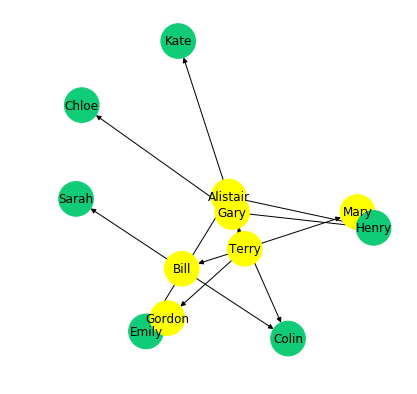

In [10]:
results = g.V().hasLabel('User').has('name', user).as_('user'). \
  both('FRIEND').aggregate('friends'). \
  both('FRIEND'). \
    where(P.neq('user')).where(P.without('friends')).aggregate('not-friends').by('name'). \
  path().by('name').aggregate('p'). \
  project('not-friends', 'paths'). \
  by(__.select('not-friends').unfold().dedup().fold()). \
  by(__.select('p')).next()

notFriends = results['not-friends']
paths = results['paths']

print(paths)

def formatter(label, colors):
    if label in notFriends:
        colors.append('#11cc77')
    else:
        colors.append('yellow')

visualisation.plotPaths(paths, formatter)

### Using Friendship Strength to Improve Recommendations

What if we wanted to base our recommendations only on resonably strong friendship bonds?

If you look at the Gremlin we used to create our graph, you'll see that each `FRIEND` edge has a `strength` property. In the following query, the traversal applies a predicate to this `strength` property. Note that we use `bothE()` rather than `both()` to position the traversal on an edge, where we then apply the predicate. We proceed only where `strength` is greater than one.

In [12]:
recommendations = (g.V().hasLabel('User').has('name', user).as_('user').  
  bothE('FRIEND').    
    has('strength', P.gt(1)).otherV().    
    aggregate('friends').  
  bothE('FRIEND').    
    has('strength', P.gt(1)).otherV().    
    where(P.neq('user')).where(P.without('friends')).  
  groupCount().by('name').  
  order(Scope.local).by(Column.values, Order.decr).
  next())

for key in recommendations.keys():
    print(key + ': ' + str(recommendations[key]))

Colin: 2
Henry: 2
Chloe: 1


Because we discount weak friendships even when traversing to immediate friends, this query can sometimes end up recommending people that have a weak direct tie to our user. But that makes sense in the context of our social domain: one of our close friebnds has a strong friendship with one of the people with whom we have a weak connection; therefore, we might predict that over time this weak bond will grow stronger.